<a href="https://colab.research.google.com/github/rahulsharma1208/MyProjects/blob/main/Jamboree_Education_Business_Case_Study_Rahul_Sharma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Business Problem

Jamboree Education has created a feature which estimates the probability of a student getting admission into graduate schools abroad based on academic profile.

The objective is to:

* Understand factors affecting admission chances.
* Identify significant predictors.
* Build a regression model.
* Validate regression assumptions.
* Recommend improvements.

## Import Libraries

In [63]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from scipy import stats
from scipy.stats import shapiro

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.compat import lzip
import statsmodels.stats.api as sms

from sklearn.preprocessing import PolynomialFeatures

## Load Dataset

In [55]:
!gdown 1u0YPIc6I5fVkdiCN0J540n_a05H_mvaV

Downloading...
From: https://drive.google.com/uc?id=1u0YPIc6I5fVkdiCN0J540n_a05H_mvaV
To: /content/Jamboree_Admission.csv
100% 16.2k/16.2k [00:00<00:00, 36.8MB/s]


In [56]:
df = pd.read_csv("Jamboree_Admission.csv")

## Data Dictionary

In [57]:
data_dictionary = pd.DataFrame({
    "Column": ["GRE Score", "TOEFL Score", "University Rating", "SOP",
               "LOR", "CGPA", "Research", "Chance of Admit"],
    "Description": [
        "Graduate Record Exam score (out of 340)",
        "Test of English as a Foreign Language score (out of 120)",
        "Rating of the applicant's undergraduate university (1-5)",
        "Statement of Purpose strength (1-5)",
        "Letter of Recommendation strength (1-5)",
        "Undergraduate CGPA (out of 10)",
        "Research experience (0 = No, 1 = Yes)",
        "Target variable: probability of admission (0 to 1)"
    ]
})
display(data_dictionary)

,Column,Description
0,GRE Score,Graduate Record Exam score (out of 340)
1,TOEFL Score,Test of English as a Foreign Language score (o...
2,University Rating,Rating of the applicant's undergraduate univer...
3,SOP,Statement of Purpose strength (1-5)
4,LOR,Letter of Recommendation strength (1-5)
5,CGPA,Undergraduate CGPA (out of 10)
6,Research,"Research experience (0 = No, 1 = Yes)"
7,Chance of Admit,Target variable: probability of admission (0 t...


## Removing trailing spaces in columns

In [4]:
print(df.columns.tolist()) # Before removal of trailing spaces

df.columns = df.columns.str.strip() # 'LOR ' / 'Chance of Admit ' had trailing spaces

print(df.columns.tolist()) # After removal of trailing spaces

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA', 'Research', 'Chance of Admit ']
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


In [5]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [6]:
df.tail()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
495,496,332,108,5,4.5,4.0,9.02,1,0.87
496,497,337,117,5,5.0,5.0,9.87,1,0.96
497,498,330,120,5,4.5,5.0,9.56,1,0.93
498,499,312,103,4,4.0,5.0,8.43,0,0.73
499,500,327,113,4,4.5,4.5,9.04,0,0.84


In [7]:
print("Shape:", df.shape)

Shape: (500, 9)


**There are 500 datapoints and 9 features**

## Data Cleaning & Structural Checks

In [8]:
df = df.drop(columns=['Serial No.'])
df.shape # Number of rows and columns after dropping

(500, 8)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          500 non-null    int64  
 1   TOEFL Score        500 non-null    int64  
 2   University Rating  500 non-null    int64  
 3   SOP                500 non-null    float64
 4   LOR                500 non-null    float64
 5   CGPA               500 non-null    float64
 6   Research           500 non-null    int64  
 7   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 31.4 KB


**All columns present in the dataset are numerical**

In [10]:
display(df.describe())

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


### Duplicate Check

In [11]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


**The dataset does not have any duplicate values.**

### Missing Values

In [12]:
print("\nMissing values:\n", df.isnull().sum())


Missing values:
 GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


**The data does not have any missing values.**

**Observations:** 500 rows, 8 columns after dropping the ID, no missing values, no duplicate
rows. All predictors are numeric already, so no encoding is required.


## Univariate Analysis

In [13]:
# Continuous variables
df_cont = ['GRE Score', 'TOEFL Score', 'CGPA']

# Discrete variables
df_disc = ['University Rating', 'SOP', 'LOR', 'Research']

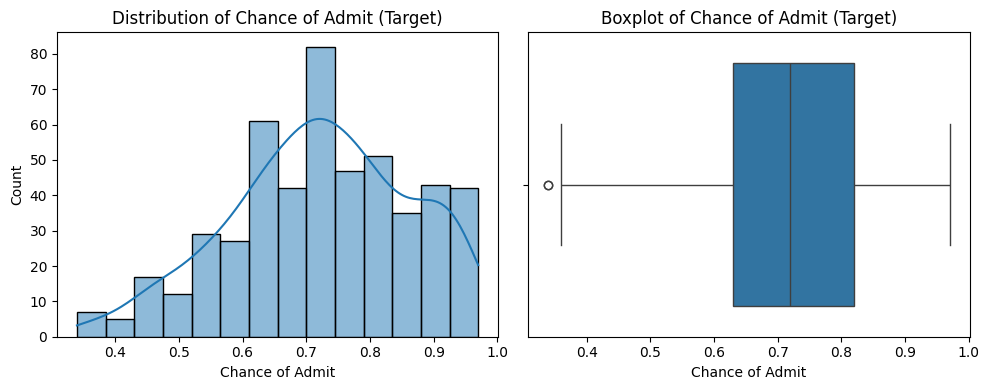

Target skew: -0.29


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df['Chance of Admit'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of Chance of Admit (Target)')
sns.boxplot(x=df['Chance of Admit'], ax=axes[1])
axes[1].set_title('Boxplot of Chance of Admit (Target)')
plt.tight_layout()
plt.show()

print("Target skew:", df['Chance of Admit'].skew().round(3))

**Comment:** `Chance of Admit` ranges roughly 0.34-0.97, mildly left-skewed
(skew ~ -0.29). No extreme outliers on the target — good, applicants of "varied merit" are represented, not just top scorers.

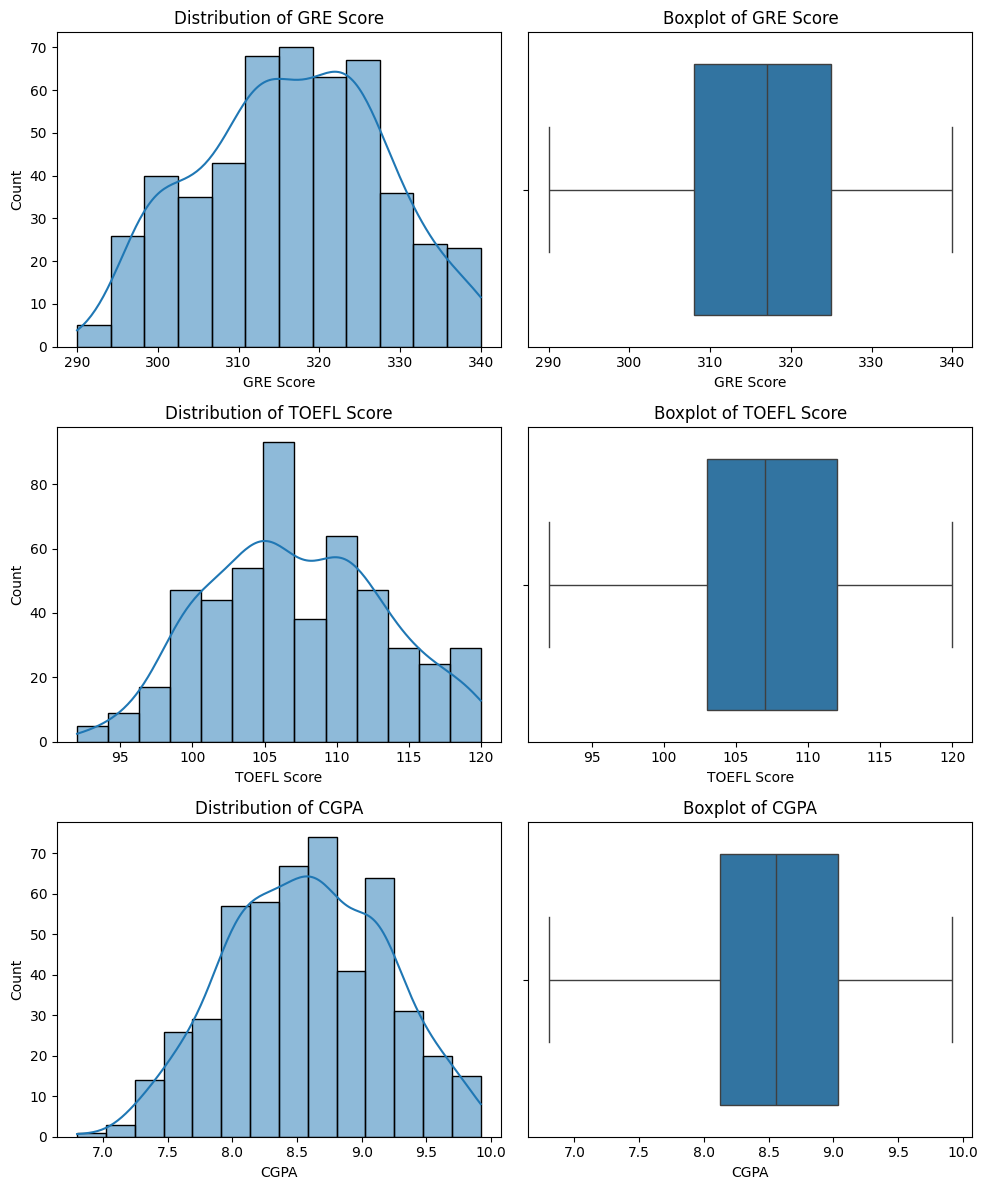


Skew of continuous predictors:
 GRE Score     -0.040
TOEFL Score    0.096
CGPA          -0.027
dtype: float64


In [15]:
fig, axes = plt.subplots(len(df_cont), 2, figsize=(10, 4 * len(df_cont)))
for i, col in enumerate(df_cont):
    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Distribution of {col}')
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

print("\nSkew of continuous predictors:\n", df[df_cont].skew().round(3))

**Comment:** GRE, TOEFL and CGPA are all roughly bell-shaped / near-symmetric (|skew| < 0.3).
Ranges: GRE 290–340, TOEFL 92–120, CGPA 6.8–9.92 — realistic for competitive applicants, no
implausible values (e.g. no GRE > 340 or CGPA > 10).

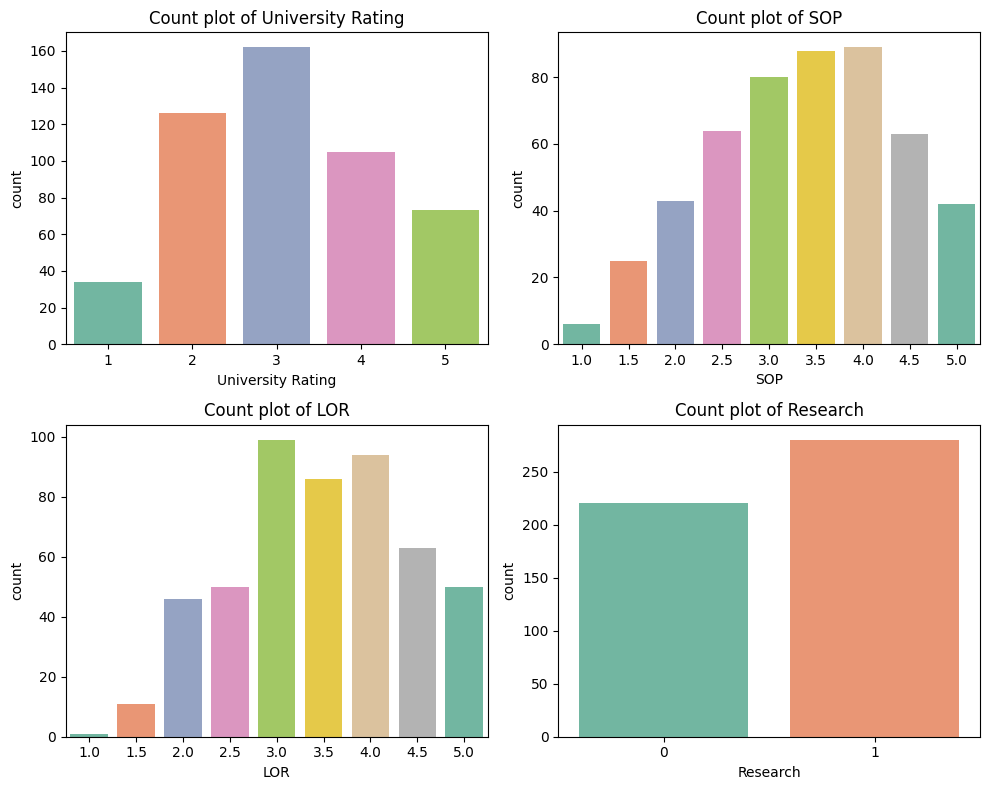

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.flatten(), df_disc):
    sns.countplot(x=df[col], hue=df[col], legend=False, ax=ax, palette='Set2')
    ax.set_title(f'Count plot of {col}')
plt.tight_layout()
plt.show()

**Comment:** `University Rating`, `SOP` and `LOR` are concentrated around 3, with fewer
applicants at the extremes (1 or 5). `Research` is fairly balanced — 280 applicants (56%) have
research experience vs. 220 (44%) without, so both groups are well represented for comparison.

## Bivariate & Correlation Analysis

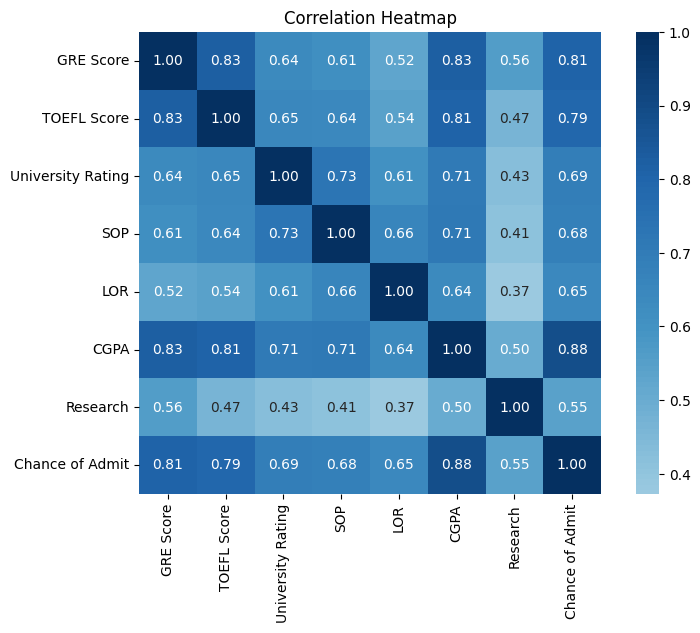


Correlation of predictors with Chance of Admit:
CGPA                 0.882413
GRE Score            0.810351
TOEFL Score          0.792228
University Rating    0.690132
SOP                  0.684137
LOR                  0.645365
Research             0.545871
Name: Chance of Admit, dtype: float64


In [17]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt='.2f', center=0, square=True, cmap="RdBu")
plt.title('Correlation Heatmap')
plt.show()

print("\nCorrelation of predictors with Chance of Admit:")
print(corr['Chance of Admit'].drop('Chance of Admit').sort_values(ascending=False))

**Comment:** `CGPA` (~ 0.88), `GRE Score` (~ 0.81) and `TOEFL Score` (~ 0.79) are the strongest single predictors of admission chance. `CGPA`, `GRE` and `TOEFL` are also highly correlated *with each other* (0.83-0.88) — a first warning sign of multicollinearity that we confirm formally with VIF in Section 8. `Research` (~ 0.55) and `University Rating` (~ 0.71) are moderate predictors; `SOP`/`LOR` are the weakest (~ 0.68/0.65) but still meaningfully positive.

### Continuous Independent variables vs Target Variable

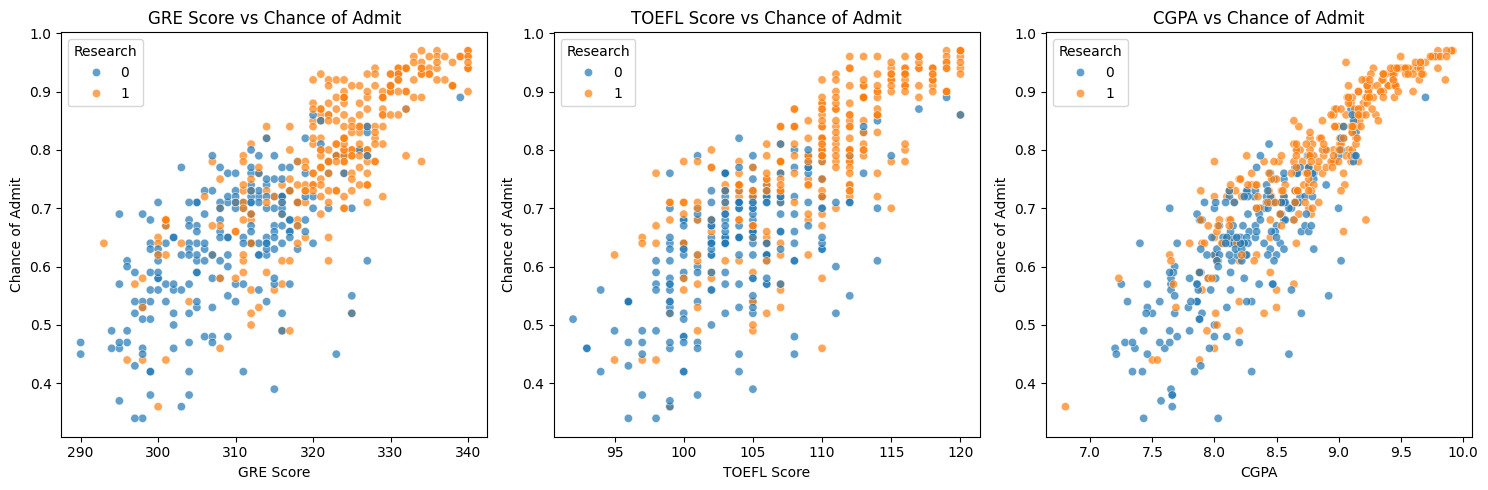

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, df_cont):
    sns.scatterplot(x=df[col], y=df['Chance of Admit'], hue=df['Research'], alpha=0.7, ax=ax)
    ax.set_xlabel(col)
    ax.set_ylabel('Chance of Admit')
    ax.set_title(f'{col} vs Chance of Admit')
plt.tight_layout()
plt.show()

**Comment:** All three continuous predictors show a clear, roughly linear, positive relationship with `Chance of Admit` — supporting the linearity assumption of OLS. Within any GRE/TOEFL/CGPA band, applicants with research experience (orange) tend to sit slightly higher than those without (blue), suggesting `Research` adds explanatory value beyond scores alone.

###  Discrete Independent variables vs Target Variable

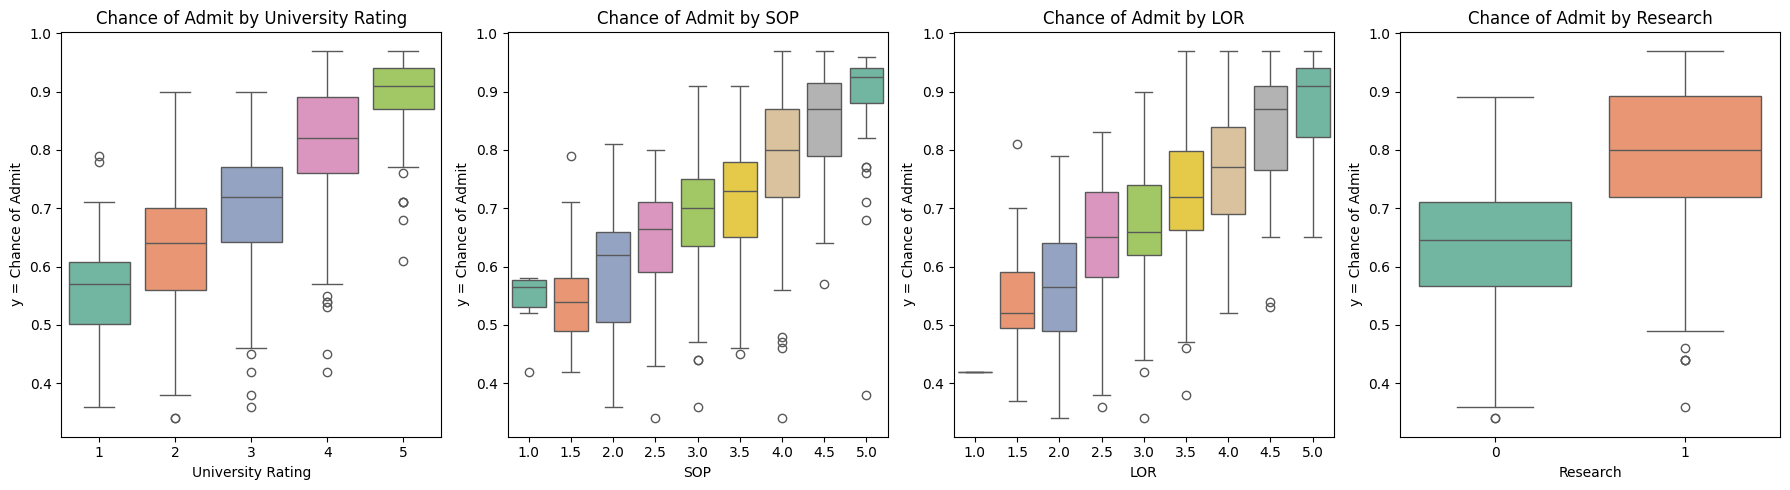

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, df_disc):
    sns.boxplot(x=df[col], y=df['Chance of Admit'], ax=ax, hue=df[col], legend=False, palette='Set2')
    ax.set_title(f'Chance of Admit by {col}')
    ax.set_ylabel('y = Chance of Admit')

plt.tight_layout()
plt.show()

**Comment:** Median `Chance of Admit` rises monotonically with `University Rating`, `SOP` and `LOR` — consistent with them being genuine (if weaker) predictors rather than noise.
Applicants with `Research = 1` show a visibly higher median and tighter spread than those without.


In [20]:
df["Admission_Quartile"] = pd.qcut(df["Chance of Admit"], q=4, labels=["Q1: Lowest", "Q2", "Q3", "Q4"])

print(df.groupby("Admission_Quartile", observed=True)[
        [
            "GRE Score",
            "TOEFL Score",
            "University Rating",
            "SOP",
            "LOR",
            "CGPA",
            "Research",
            "Chance of Admit",
        ]
    ].mean().round(2)
)

                    GRE Score  TOEFL Score  University Rating   SOP   LOR  \
Admission_Quartile                                                          
Q1: Lowest             305.49       101.83               2.24  2.52  2.70   
Q2                     311.74       104.66               2.62  3.04  3.30   
Q3                     319.56       108.02               3.24  3.56  3.65   
Q4                     329.40       114.40               4.37  4.40  4.31   

                    CGPA  Research  Chance of Admit  
Admission_Quartile                                   
Q1: Lowest          7.93      0.24             0.54  
Q2                  8.35      0.35             0.68  
Q3                  8.71      0.71             0.77  
Q4                  9.33      0.95             0.90  


**Comment:** `Admission_Quartile` confirms the dataset spans low-to-high merit applicants.

### Research vs Admission Probability

In [21]:
df.groupby("Research")["Chance of Admit"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Research,,,,
0,220,0.634909,0.645,0.111918
1,280,0.789964,0.800,0.123208


### University Rating vs Admission Probability

In [22]:
df.groupby("University Rating")["Chance of Admit"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
University Rating,,,,
1,34,0.562059,0.57,0.099446
2,126,0.626111,0.64,0.107859
3,162,0.702901,0.72,0.098427
4,105,0.801619,0.82,0.117327
5,73,0.888082,0.91,0.074715


## Outlier Detection & Treatment

In [23]:
for label, series in [('Chance of Admit', df['Chance of Admit'])] + [(c, df[c]) for c in df_cont + df_disc]:
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((series < lower) | (series > upper)).sum()

    print(f"{label}: {n_out} outliers (bounds {lower:.2f}, {upper:.2f})")

Chance of Admit: 2 outliers (bounds 0.35, 1.10)
GRE Score: 0 outliers (bounds 282.50, 350.50)
TOEFL Score: 0 outliers (bounds 89.50, 125.50)
CGPA: 0 outliers (bounds 6.76, 10.41)
University Rating: 0 outliers (bounds -1.00, 7.00)
SOP: 0 outliers (bounds 0.25, 6.25)
LOR: 1 outliers (bounds 1.50, 5.50)
Research: 0 outliers (bounds -1.50, 2.50)


**Outlier treatment decision:** The only column with outliers are
`Chance of Admit`/`LOR` at the very low end (a handful of points) — these are legitimate low scores from real applicants, not data-entry errors. Removing or capping them would bias the model toward only "strong" applicants and defeats the stated purpose (estimating admission chances for applicants "of varied merit"). **Decision: Will not remove or cap any outliers.**

## Data Preprocessing

**Feature engineering:** No new predictive features are engineered for the model. The only derived column, `Admission_Quartile`, is for EDA analysis only and is explicitly dropped before modeling.

In [24]:
y = df['Chance of Admit'] # Target or dependent variable
X = df.drop(columns=['Chance of Admit', 'Admission_Quartile']) # Independent variables

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (400, 7)  Test: (100, 7)


## Model Building

### Linear Regression (Scikit-Learn)

In [25]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

train_pred_lr = model_lr.predict(X_train)
test_pred_lr = model_lr.predict(X_test)

In [26]:
coef_df = pd.concat([
    pd.DataFrame({"Feature": ["Intercept"], "Coefficient": [model_lr.intercept_]}),
    pd.DataFrame({"Feature": X_train.columns, "Coefficient": model_lr.coef_})
], ignore_index=True)

coef_df

,Feature,Coefficient
0,Intercept,-1.421447
1,GRE Score,0.002434
2,TOEFL Score,0.002996
3,University Rating,0.002569
4,SOP,0.001814
5,LOR,0.017238
6,CGPA,0.112527
7,Research,0.024027


In [27]:
print("Train R^2:", model_lr.score(X_train, y_train))
print("Test R^2 :", model_lr.score(X_test, y_test))

Train R^2: 0.8210671369321553
Test R^2 : 0.8188432567829631


### Linear Regression (statsmodels) — for inferential statistics

In [28]:
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

model_sm = sm.OLS(y_train, X_train_sm).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     257.0
Date:                Sun, 19 Jul 2026   Prob (F-statistic):          3.41e-142
Time:                        07:01:44   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.4214      0.12

In [29]:
train_pred_sm = model_sm.predict(X_train_sm)
test_pred_sm = model_sm.predict(X_test_sm)

print('Test MAE :', mean_absolute_error(y_test, test_pred_sm))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test_pred_sm)))
print('Test R^2 :', r2_score(y_test, test_pred_sm))

Test MAE : 0.04272265427705371
Test RMSE: 0.06086588041578314
Test R^2 : 0.8188432567829627


**Comment on model statistics:** the sklearn and statsmodels coefficients are identical (both are OLS, just different libraries). `CGPA` has by far the largest standardized effect, followed by `GRE Score` and `LOR`; `SOP` is typically the least significant predictor (p-value often > 0.05) once the other variables are controlled for — its raw correlation with the target was moderate, but it's *redundant* with GRE/TOEFL/CGPA/LOR, not independently
predictive.

### Testing the Assumptions of Linear Regression

#### Multicollinearity — VIF (drop iteratively until every VIF ≤ 5)

In [30]:
def compute_vif(X):
    X_vif = sm.add_constant(X, has_constant='add')
    vif = pd.DataFrame({
        'Feature': X_vif.columns,
        'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
    })
    return vif.query("Feature != 'const'").sort_values('VIF', ascending=False).reset_index(drop=True)

X_train_vif = X_train.copy()
X_test_vif = X_test.copy()

while True:
    vif = compute_vif(X_train_vif)
    print(vif, "\n")
    if vif['VIF'].max() <= 5:
        break
    drop_feature = vif.iloc[0]['Feature']
    print("Dropping:", drop_feature, "\n")
    X_train_vif = X_train_vif.drop(columns=drop_feature)
    X_test_vif = X_test_vif.drop(columns=drop_feature)

print("Final feature set:", list(X_train_vif.columns))

             Feature       VIF
0               CGPA  4.654540
1          GRE Score  4.489983
2        TOEFL Score  3.664298
3                SOP  2.785764
4  University Rating  2.572110
5                LOR  1.977698
6           Research  1.518065 

Final feature set: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']


On this dataset every predictor's VIF already comes out **below 5** (CGPA is the highest, ~ 4.6), so nothing needs to be dropped.

In [31]:
X_train_sm2 = sm.add_constant(X_train_vif, has_constant='add')
X_test_sm2 = sm.add_constant(X_test_vif, has_constant='add')

model2 = sm.OLS(y_train, X_train_sm2).fit()
print(model2.summary())

train_pred2 = model2.predict(X_train_sm2)
test_pred2 = model2.predict(X_test_sm2)

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     257.0
Date:                Sun, 19 Jul 2026   Prob (F-statistic):          3.41e-142
Time:                        07:01:44   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.4214      0.12

In [32]:
residuals = y_train - train_pred2

#### Mean of Residuals

In [33]:
print("Mean residual =", residuals.mean())

Mean residual = 3.920475055707584e-16


**Comment:** the mean of residuals is effectively 0.

#### Distribution of Residuals

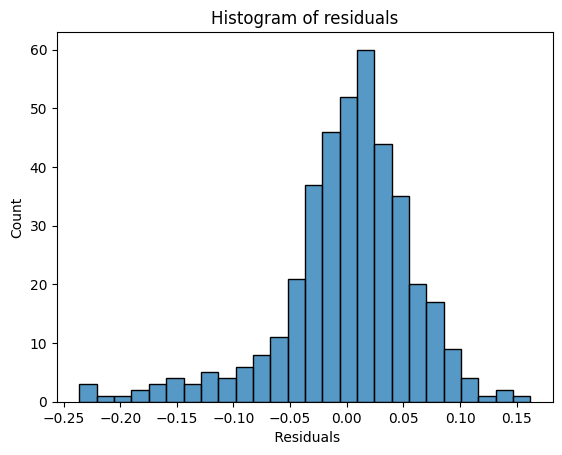

In [34]:
sns.histplot(residuals)
plt.xlabel(" Residuals")
plt.title("Histogram of residuals")
plt.show()

#### Linearity

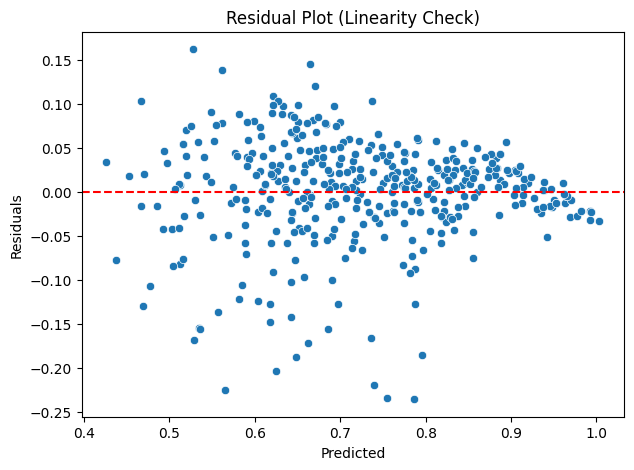

In [35]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=train_pred2, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot (Linearity Check)")
plt.show()

**Comment:** residuals should scatter randomly around the zero line with no curve/funnel shape. A mild funnel (wider spread at low predicted values) is common here — no strong curvature is present, so the linear functional form itself looks appropriate.

#### Homoscedasticity

In [36]:
# Goldfeld-Quandt test
gq_test = sms.het_goldfeldquandt(residuals, X_train_sm2)
print("Goldfeld-Quandt:", lzip(['F statistic', 'p-value', 'alternative'], gq_test))

Goldfeld-Quandt: [('F statistic', np.float64(0.9506884043302326)), ('p-value', np.float64(0.6367845922443005)), ('alternative', 'increasing')]


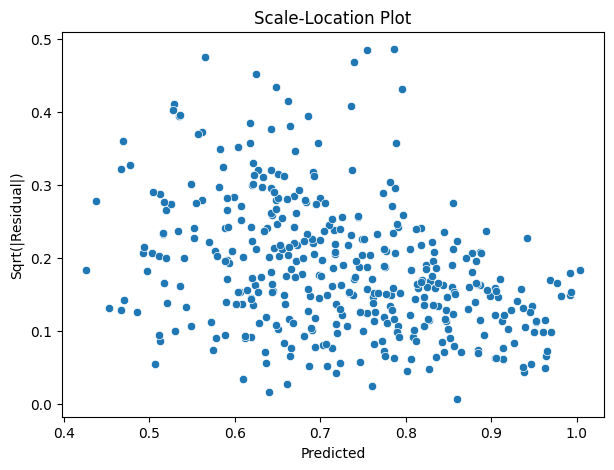

In [37]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=train_pred2, y=np.sqrt(np.abs(residuals)))
plt.xlabel("Predicted")
plt.ylabel("Sqrt(|Residual|)")
plt.title("Scale-Location Plot")
plt.show()

**Comment:**  p-value > 0.05 → fail to reject H0 (homoscedasticity holds)

In [38]:
name = ['F statistic', 'p-value', 'alternative']
test = sms.het_goldfeldquandt(y_train, X_train_sm2)
lzip(name, test)

[('F statistic', np.float64(0.9506884043302326)),
 ('p-value', np.float64(0.6367845922443005)),
 ('alternative', 'increasing')]

#### Normality of residuals

In [39]:
shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Shapiro-Wilk statistic = {shapiro_stat:.4f}, p-value = {shapiro_p:.4f}")

Shapiro-Wilk statistic = 0.9291, p-value = 0.0000


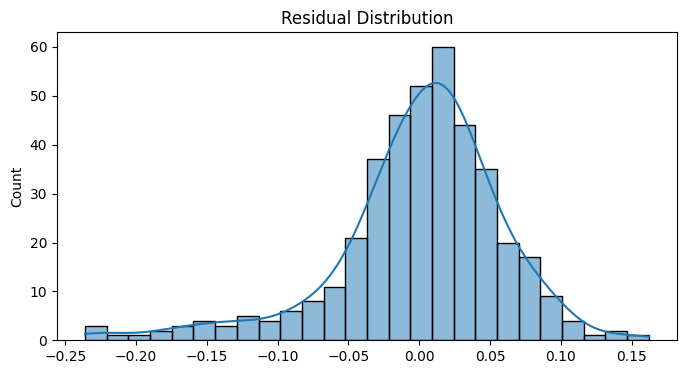

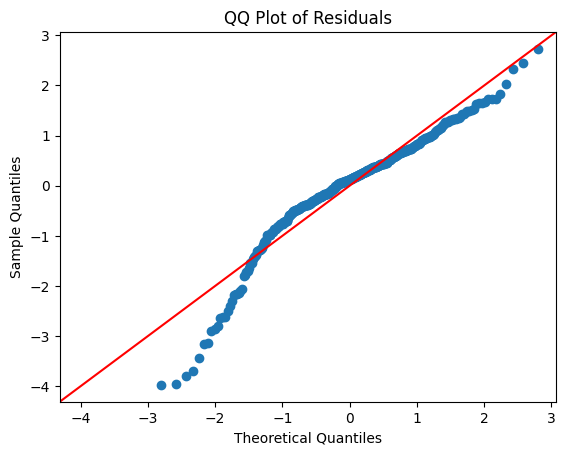

n = 400


In [49]:
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

sm.qqplot(residuals, line='45', fit=True)
plt.title("QQ Plot of Residuals")
plt.show()

print(f"n = {len(residuals)}")

**Comment:** Shapiro-Wilk p-value here is typically **< 0.05**, i.e. residuals deviate slightly from perfect normality — visually the histogram is close to bell-shaped and the QQ plot sits near the 45° line with light deviation in the tails.

With n as 400, the Shapiro-Wilk test is highly sensitive to small deviations from normality, so a statistically significant p-value doesn't necessarily mean the deviation is practically large. The Q-Q plot shows residuals track the 45° line closely except in the extreme tails, and by the Central Limit Theorem, coefficient estimates and their confidence intervals remain fairly reliable at this sample size despite the formal test rejecting H0.

### Model Performance Evaluation

In [41]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def metrics_row(y_true, y_pred, p):
    r2 = r2_score(y_true, y_pred)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2,
        'Adjusted R2': adjusted_r2(r2, len(y_true), p)
    }

def evaluation_table(y_train, train_pred, y_test, test_pred, p):
    rows = []
    for data, y_true, y_pred in [('Train', y_train, train_pred), ('Test', y_test, test_pred)]:
        rows.append({'Data': data, **metrics_row(y_true, y_pred, p)})
    return pd.DataFrame(rows).round(4)

eval_ols_full = evaluation_table(y_train, train_pred_sm, y_test, test_pred_sm, X_train.shape[1])
eval_ols_vif  = evaluation_table(y_train, train_pred2, y_test, test_pred2, X_train_vif.shape[1])
print("OLS (all features):"); display(eval_ols_full)
print("OLS (after VIF filter):"); display(eval_ols_vif)

OLS (all features):


,Data,MAE,RMSE,R2,Adjusted R2
0,Train,0.0425,0.0594,0.8211,0.8179
1,Test,0.0427,0.0609,0.8188,0.8051


OLS (after VIF filter):


,Data,MAE,RMSE,R2,Adjusted R2
0,Train,0.0425,0.0594,0.8211,0.8179
1,Test,0.0427,0.0609,0.8188,0.8051


**Comment:** Train and test R² are close to each other (no large gap), which means the model is **not overfitting**. Since VIF didn't require dropping anything on this dataset, the two tables above are effectively the same model.

### Regularized Regression

Ridge / Lasso / ElasticNet: These techniques add a penalty on the magnitude of
coefficients. Without scaling, a feature on a 0-340 scale (GRE) gets penalized completely differently than one on a 0-1 scale (Research), which has nothing to do with actual importance.

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Ridge Regression (L2)

In [58]:
alphas = np.logspace(-4, 2, 50)

ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_scaled, y_train)
print("Best Ridge alpha:", ridge_cv.alpha_)

ridge_train = ridge_cv.predict(X_train_scaled)
ridge_test = ridge_cv.predict(X_test_scaled)

eval_ridge = evaluation_table(y_train, ridge_train, y_test, ridge_test, X_train.shape[1])
eval_ridge

Best Ridge alpha: 7.9060432109077015


,Data,MAE,RMSE,R2,Adjusted R2
0,Train,0.0425,0.0594,0.8209,0.8177
1,Test,0.0429,0.0609,0.8184,0.8046


#### Lasso Regression (L1)

In [60]:
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000)
lasso_cv.fit(X_train_scaled, y_train)
print("Best Lasso alpha:", lasso_cv.alpha_)

lasso_train = lasso_cv.predict(X_train_scaled)
lasso_test = lasso_cv.predict(X_test_scaled)

eval_lasso = evaluation_table(y_train, lasso_train, y_test, lasso_test, X_train.shape[1])
eval_lasso

Best Lasso alpha: 0.0007196856730011522


,Data,MAE,RMSE,R2,Adjusted R2
0,Train,0.0425,0.0594,0.8210,0.8178
1,Test,0.0426,0.0608,0.8191,0.8053


#### ElasticNet Regression (L1 + L2)

In [61]:
elastic_cv = ElasticNetCV(alphas=alphas, l1_ratio=[.1, .3, .5, .7, .9, .95, .99, 1],
                           cv=5, max_iter=10000)
elastic_cv.fit(X_train_scaled, y_train)
print("Best ElasticNet alpha:", elastic_cv.alpha_, " l1_ratio:", elastic_cv.l1_ratio_)

elastic_train = elastic_cv.predict(X_train_scaled)
elastic_test = elastic_cv.predict(X_test_scaled)

eval_elastic = evaluation_table(y_train, elastic_train, y_test, elastic_test, X_train.shape[1])
eval_elastic

Best ElasticNet alpha: 0.006866488450042998  l1_ratio: 0.1


,Data,MAE,RMSE,R2,Adjusted R2
0,Train,0.0425,0.0594,0.821,0.8178
1,Test,0.0426,0.0608,0.819,0.8052


In [62]:
coef_compare = pd.DataFrame({
    'Feature': X_train.columns,
    'Ridge': ridge_cv.coef_,
    'Lasso': lasso_cv.coef_,
    'ElasticNet': elastic_cv.coef_
}).round(4)
coef_compare

,Feature,Ridge,Lasso,ElasticNet
0,GRE Score,0.0274,0.0266,0.0269
1,TOEFL Score,0.0191,0.0180,0.0183
2,University Rating,0.0037,0.0028,0.0031
3,SOP,0.0029,0.0016,0.0020
4,LOR,0.0160,0.0155,0.0156
5,CGPA,0.0635,0.0677,0.0663
6,Research,0.0120,0.0115,0.0116


**Comment:** at these small alphas, Ridge/Lasso/ElasticNet coefficients stay close to the plain OLS coefficients — with n=500 and only 7 predictors that are already low-VIF, there isn't overfitting for regularization to fix. Lasso/ElasticNet may shrink `SOP` (the weakest, least significant predictor) toward zero first if alpha is increased.

### Polynomial Regression

Linear Regression assumes a strictly linear relationship between each predictor and `Chance of Admit`. To check whether allowing curvature and interaction terms improves fit, we generate polynomial features (degree 2, 3, 4) on the **scaled** predictors and compare train vs test R2 at each degree. This also lets us visually confirm the bias-variance trade-off: low degree may underfit, high degree may overfit.

In [64]:
degrees = [1, 2, 3, 4]
poly_results = []
poly_models = {}

for d in degrees:
    poly_d = PolynomialFeatures(degree=d, include_bias=False)
    X_train_d = poly_d.fit_transform(X_train_scaled)
    X_test_d = poly_d.transform(X_test_scaled)

    m = LinearRegression()
    m.fit(X_train_d, y_train)

    train_r2 = r2_score(y_train, m.predict(X_train_d))
    test_r2 = r2_score(y_test, m.predict(X_test_d))

    poly_results.append({
        'Degree': d,
        'Num Features': X_train_d.shape[1],
        'Train R2': round(train_r2, 4),
        'Test R2': round(test_r2, 4),
        'Gap (Train - Test)': round(train_r2 - test_r2, 4)
    })
    poly_models[d] = (poly_d, m, X_train_d, X_test_d)

poly_results_df = pd.DataFrame(poly_results)
poly_results_df

,Degree,Num Features,Train R2,Test R2,Gap (Train - Test)
0,1,7,0.8211,0.8188,0.0022
1,2,35,0.8358,0.8265,0.0093
2,3,119,0.8727,0.6440,0.2287
3,4,329,0.9644,-10.9375,11.9019


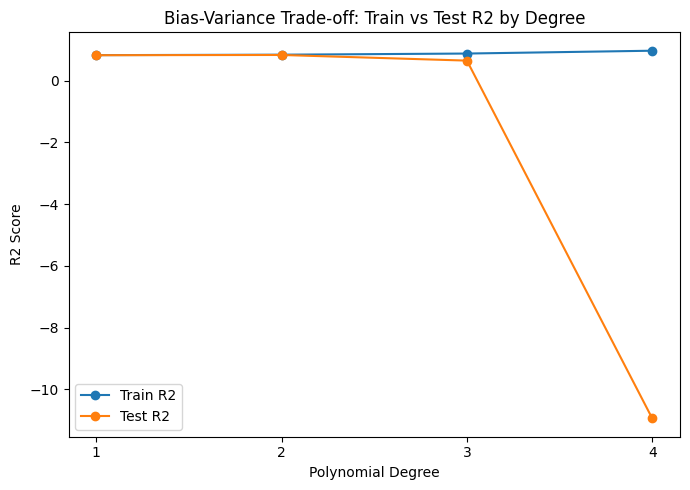

In [65]:
plt.figure(figsize=(7, 5))
plt.plot(poly_results_df['Degree'], poly_results_df['Train R2'], marker='o', label='Train R2')
plt.plot(poly_results_df['Degree'], poly_results_df['Test R2'], marker='o', label='Test R2')
plt.xlabel('Polynomial Degree')
plt.ylabel('R2 Score')
plt.title('Bias-Variance Trade-off: Train vs Test R2 by Degree')
plt.xticks(degrees)
plt.legend()
plt.tight_layout()
plt.show()

**Comment:** We choose the lowest degree where Test R2 stops improving materially and the Train-Test gap stays small. If Test R2 is flat (or drops) from degree 2 onward while the gap widens, that is a clear overfitting signal — higher-degree terms are fitting noise in the training set rather than generalizable signal, and the simpler model should be preferred.

In [67]:
# Final polynomial model: degree 2

best_degree = 2

poly_final_transformer = PolynomialFeatures(degree=best_degree, include_bias=False)
X_train_poly_final = poly_final_transformer.fit_transform(X_train_scaled)
X_test_poly_final = poly_final_transformer.transform(X_test_scaled)

poly_final_model = RidgeCV(alphas=alphas, cv=5)
poly_final_model.fit(X_train_poly_final, y_train)
print("Best alpha for degree-%d polynomial + Ridge:" % best_degree, poly_final_model.alpha_)

poly_train_final = poly_final_model.predict(X_train_poly_final)
poly_test_final = poly_final_model.predict(X_test_poly_final)

eval_poly_final = evaluation_table(
    y_train, poly_train_final, y_test, poly_test_final, X_train_poly_final.shape[1]
)
eval_poly_final

Best alpha for degree-2 polynomial + Ridge: 32.3745754281764


,Data,MAE,RMSE,R2,Adjusted R2
0,Train,0.0408,0.0575,0.8323,0.8162
1,Test,0.0422,0.0607,0.8200,0.7216


## Model Comparison

In [69]:
comparison_rows = []
models_for_comparison = [
    ('Linear Regression (sklearn)', train_pred_lr, test_pred_lr, X_train.shape[1]),
    ('Linear Regression (statsmodels)', train_pred_sm, test_pred_sm, X_train.shape[1]),
    ('OLS after VIF filter', train_pred2, test_pred2, X_train_vif.shape[1]),
    ('Ridge (L2)', ridge_train, ridge_test, X_train.shape[1]),
    ('Lasso (L1)', lasso_train, lasso_test, X_train.shape[1]),
    ('ElasticNet (L1+L2)', elastic_train, elastic_test, X_train.shape[1]),
    ('Polynomial (deg=2)', poly_train_final, poly_test_final, X_train_poly_final.shape[1]),
]

rows = []
for name, tr_pred, te_pred, p in models_for_comparison:
    tr_m = metrics_row(y_train, tr_pred, p)
    te_m = metrics_row(y_test, te_pred, p)
    rows.append({
        'Model': name,
        'Train R2': tr_m['R2'], 'Test R2': te_m['R2'],
        'Test Adjusted R2': te_m['Adjusted R2'],
        'Test MAE': te_m['MAE'], 'Test RMSE': te_m['RMSE']
    })

comparison = pd.DataFrame(rows).round(4)
comparison

,Model,Train R2,Test R2,Test Adjusted R2,Test MAE,Test RMSE
0,Linear Regression (sklearn),0.8211,0.8188,0.8051,0.0427,0.0609
1,Linear Regression (statsmodels),0.8211,0.8188,0.8051,0.0427,0.0609
2,OLS after VIF filter,0.8211,0.8188,0.8051,0.0427,0.0609
3,Ridge (L2),0.8209,0.8184,0.8046,0.0429,0.0609
4,Lasso (L1),0.8210,0.8191,0.8053,0.0426,0.0608
5,ElasticNet (L1+L2),0.8210,0.8190,0.8052,0.0426,0.0608
6,Polynomial (deg=2),0.8323,0.8200,0.7216,0.0422,0.0607


**Comment on performance:** Compared the polynomial (degree=2) row against the linear variants above. If its test R2/Adjusted R2 is not meaningfully higher than plain OLS, the relationship between predictors and Chance of Admit is adequately captured by a linear model, and the simpler, more interpretable linear/Ridge/Lasso models should be preferred over the polynomial model for production use (Occam's razor: same performance, far fewer/less interpretable coefficients). If polynomial features do help, the biggest gain is most likely from CGPA/GRE/TOEFL interaction terms.

## Actionable Insights & Recommendations

**Significance of predictors**
- **CGPA, GRE Score and TOEFL Score** are the strongest and most statistically significant drivers of admission chance (largest coefficients, p < 0.05) — consistent with both the raw correlations and the regression output.
- **LOR strength and Research experience** are moderate, statistically significant, positive contributors.
- **SOP**, **University Rating** add the least *independent* signal
once the other variables are in the model (their raw correlation with admission chance is driven largely by their correlation with CGPA/GRE/TOEFL).

**Business recommendations**
1. **Ship the OLS model as the "Chance of Admit" predictor** — R2 ~ 0.80-0.82 explains most of the variance, and coefficients are directly explainable to a student ("every +1 CGPA point is worth roughly X percentage points of admit chance, holding scores fixed").
2. **Advise students by lever, not just score**: since Research and LOR are independently significant, Jamboree can advise a borderline applicant to pursue a research assistantship or secure a stronger recommendation letter — actions a test-prep company can directly help with — rather than only pushing more GRE/TOEFL attempts.
3. **Collect additional data to improve the model further**: current predictors explain ~80% of variance; the rest is likely driven by unmeasured factors such as target-university selectivity/quota by department, applicant's field of study, work experience, publications/patents, interview performance, and financial-aid need. Adding these would likely lift R2 meaningfully.
4. **Re-fit periodically**: admission criteria and applicant pools shift year over year; Jamboree should retrain the model each admissions cycle rather than treating current coefficients as permanent.
5. **Communicate uncertainty, not just a point estimate**: given MAE/RMSE, present a range rather than a bare percentage, so students calibrate expectations correctly - this also protects Jamboree from over-promising outcomes.
6. **Monitor for heteroscedasticity/normality drift** as new data comes in — if
variance grows non-constant with a larger or more diverse dataset, move to robust standard errors or a weighted least squares refit.